In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

sns.set_theme(style="whitegrid", font="DejaVu Sans")
INK, ACC, ACC2, GREEN = "#1a1a2e", "#c1121f", "#2a6f97", "#6a994e"

# ---- configuration -------------------------------------------------------
CSV_PATH   = "climate_dengue_city_merged.csv"
CANDIDATES = ["tave","tmin","tmax","heat_index","rh","pr","pr_weekly_sum",
              "wind_speed","solar_rad","uv_rad"]
RETAINED   = ["tave","rh","pr_weekly_sum","wind_speed","solar_rad"]  # Step 6 a-priori set
MAXLAG          = 16          # weeks scanned in the CCF
PLAUSIBLE       = (0, 12)     # biologically plausible lag window for selection
VIF_THRESHOLD   = 5.0
CV_INIT, CV_HORIZON = 260, 26 # rolling-origin: 5-yr initial train, 26-wk test blocks
DW_OK = (1.5, 2.5)            # Durbin-Watson band for "no autocorrelation"

# ---- helpers -------------------------------------------------------------
def vif_table(frame, cols):
    """VIF_j = 1/(1-R^2_j) from regressing predictor j on the others (numpy, no statsmodels)."""
    rows = []
    for c in cols:
        others = [x for x in cols if x != c]
        X = np.column_stack([np.ones(len(frame)), frame[others].values.astype(float)])
        y = frame[c].values.astype(float)
        b, *_ = np.linalg.lstsq(X, y, rcond=None)
        r2 = 1 - ((y - X @ b)**2).sum() / ((y - y.mean())**2).sum()
        rows.append((c, np.inf if r2 >= 1 else 1/(1-r2)))
    return pd.DataFrame(rows, columns=["var","VIF"]).sort_values("VIF", ascending=False, ignore_index=True)

def seasonal_matrix(dates, t0):
    """Annual + semi-annual harmonics and an absolute linear trend (years since t0)."""
    doy = dates.dt.dayofyear.values
    ph  = 2*np.pi*doy/365.25
    trend = (dates - t0).dt.days.values / 365.25
    return np.column_stack([np.sin(ph), np.cos(ph), np.sin(2*ph), np.cos(2*ph), trend])
SEAS_COLS = ["sin1","cos1","sin2","cos2","trend"]

def deseasonalize(series, seas):
    """Residuals of series ~ [1, seasonal matrix] — removes the annual cycle & trend."""
    X = np.column_stack([np.ones(len(series)), seas])
    b, *_ = np.linalg.lstsq(X, np.asarray(series, float), rcond=None)
    return np.asarray(series, float) - X @ b

##### Step 3 — Load and clean
Canonical load used by every downstream cell. Verifies the 780-week sequence, missing values, week spacing, partial weeks, and the zero-case share that motivates the transform.

In [5]:
df = pd.read_csv(CSV_PATH)
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%y")   # 'week_start' was an old alias of 'date'
df = df.sort_values("date").reset_index(drop=True)
T0 = df["date"].min()

print(f"Rows: {len(df)}   City: {df['city'].unique().tolist()}")
print(f"Range: {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print("Missing values:", int(df.isna().sum().sum()))
gaps = df["date"].diff().dt.days
print("Weeks not exactly 7 days after previous:", int((gaps.ne(7) & gaps.notna()).sum()))
print("days_in_week counts:", df["days_in_week"].value_counts().sort_index().to_dict())
for t in (0,1,2,5):
    c = int((df["dengue_cases"] <= t).sum())
    print(f"  weeks with cases <= {t}: {c} ({100*c/len(df):.1f}%)")

Rows: 780   City: ['Dagupan City']
Range: 2008-01-07 to 2022-12-26
Missing values: 0
Weeks not exactly 7 days after previous: 2
days_in_week counts: {6: 1, 7: 779}
  weeks with cases <= 0: 85 (10.9%)
  weeks with cases <= 1: 160 (20.5%)
  weeks with cases <= 2: 241 (30.9%)
  weeks with cases <= 5: 426 (54.6%)


##### Step 5 — Outcome transformation
Weekly counts are right-skewed and overdispersed, so the outcome is modeled as `log(cases + 1)` — this stabilizes variance and admits zero-case weeks. The Negative Binomial refit in Step 12 is the honest cross-check on modeling counts with OLS.

In [18]:
df["log_cases"] = np.log1p(df["dengue_cases"])
print(f"Skewness raw:        {stats.skew(df['dengue_cases']):.2f}")
print(f"Skewness log(x+1):   {stats.skew(df['log_cases']):.2f}")
print(f"Variance / mean:     {df['dengue_cases'].var()/df['dengue_cases'].mean():.1f}  (>>1 = overdispersed)")

Skewness raw:        2.24
Skewness log(x+1):   -0.02
Variance / mean:     11.5  (>>1 = overdispersed)


##### Step 4 — Exploratory data analysis
Time series, raw vs log distribution, seasonal profile, and the rainfall–cases offset. These panels populate Results IV-A.

count    780.00000
mean       8.20000
std        9.68985
min        0.00000
25%        2.00000
50%        4.00000
75%       11.00000
max       70.00000


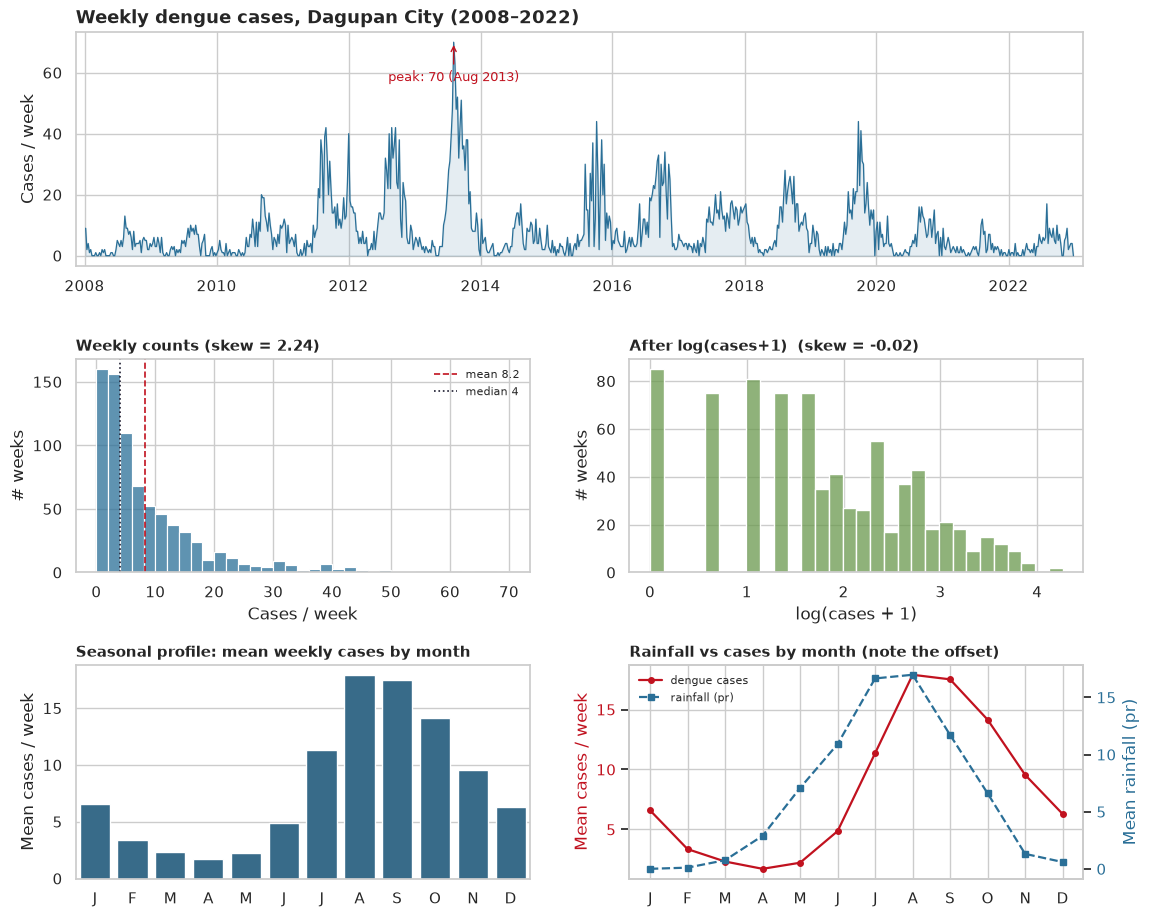

In [19]:
d0 = df["dengue_cases"]
df["month"] = df["date"].dt.month
print(d0.describe().to_string())

fig = plt.figure(figsize=(13,11))
gs = fig.add_gridspec(3,2, height_ratios=[1.1,1,1], hspace=0.42, wspace=0.22)

ax1 = fig.add_subplot(gs[0,:])
ax1.plot(df["date"], d0, lw=0.9, color=ACC2); ax1.fill_between(df["date"], d0, color=ACC2, alpha=0.12)
ax1.set_title("Weekly dengue cases, Dagupan City (2008–2022)", fontsize=13, fontweight="bold", loc="left")
ax1.set_ylabel("Cases / week"); ax1.margins(x=0.01)
mx = d0.idxmax()
ax1.annotate(f"peak: {int(d0.max())} ({df.loc[mx,'date']:%b %Y})",
             xy=(df.loc[mx,'date'], d0.max()), xytext=(0,-28), textcoords="offset points",
             fontsize=9, color=ACC, ha="center", arrowprops=dict(arrowstyle="->", color=ACC, lw=1))

ax2 = fig.add_subplot(gs[1,0])
sns.histplot(d0, bins=35, color=ACC2, edgecolor="white", ax=ax2)
ax2.set_title(f"Weekly counts (skew = {stats.skew(d0):.2f})", fontsize=11, fontweight="bold", loc="left")
ax2.set_xlabel("Cases / week"); ax2.set_ylabel("# weeks")
ax2.axvline(d0.mean(), color=ACC, ls="--", lw=1.2, label=f"mean {d0.mean():.1f}")
ax2.axvline(d0.median(), color=INK, ls=":", lw=1.2, label=f"median {d0.median():.0f}")
ax2.legend(fontsize=8, frameon=False)

ax3 = fig.add_subplot(gs[1,1])
sns.histplot(np.log1p(d0), bins=30, color=GREEN, edgecolor="white", ax=ax3)
ax3.set_title(f"After log(cases+1)  (skew = {stats.skew(np.log1p(d0)):.2f})", fontsize=11, fontweight="bold", loc="left")
ax3.set_xlabel("log(cases + 1)"); ax3.set_ylabel("# weeks")

ax4 = fig.add_subplot(gs[2,0])
mp = df.groupby("month")["dengue_cases"].mean().reset_index()
sns.barplot(data=mp, x="month", y="dengue_cases", color=ACC2, ax=ax4)
ax4.set_xticks(range(12)); ax4.set_xticklabels(list("JFMAMJJASOND"))
ax4.set_title("Seasonal profile: mean weekly cases by month", fontsize=11, fontweight="bold", loc="left")
ax4.set_xlabel(""); ax4.set_ylabel("Mean cases / week")

ax5 = fig.add_subplot(gs[2,1])
cases_m = df.groupby("month")["dengue_cases"].mean(); rain_m = df.groupby("month")["pr"].mean()
l1 = ax5.plot(cases_m.index, cases_m.values, color=ACC, marker="o", ms=4, lw=1.6, label="dengue cases")
ax5.set_ylabel("Mean cases / week", color=ACC); ax5.tick_params(axis="y", labelcolor=ACC)
axb = ax5.twinx(); axb.grid(False)
l2 = axb.plot(rain_m.index, rain_m.values, color=ACC2, marker="s", ms=4, lw=1.6, ls="--", label="rainfall (pr)")
axb.set_ylabel("Mean rainfall (pr)", color=ACC2); axb.tick_params(axis="y", labelcolor=ACC2)
ax5.set_xticks(range(1,13)); ax5.set_xticklabels(list("JFMAMJJASOND"))
ax5.set_title("Rainfall vs cases by month (note the offset)", fontsize=11, fontweight="bold", loc="left")
ax5.legend(l1+l2, [x.get_label() for x in l1+l2], fontsize=8, frameon=False, loc="upper left")
plt.show()

##### Step 6 — Collinearity screening *(IV-B)*
Principled first: group the candidates into blocks and keep one representative per block on
substantive grounds — `pr_weekly_sum` over `pr` (identical at weekly resolution; keep the weekly
total), mean temperature `tave` as the temperature term, `heat_index` dropped (a temp×humidity
composite that double-counts), and `solar_rad` over `uv_rad` (r ≈ 0.99). VIF is then a
**confirmatory** check on the a-priori set, not the selector.

Strongly correlated candidate pairs (|r| > 0.8):
  tave           vs tmin            r = +0.86
  tave           vs tmax            r = +0.92
  tmax           vs uv_rad          r = +0.86
  heat_index     vs tave            r = +0.94
  heat_index     vs tmin            r = +0.94
  pr             vs pr_weekly_sum   r = +1.00
  solar_rad      vs tmax            r = +0.83
  solar_rad      vs uv_rad          r = +0.99

Full candidate-set VIF (shows the redundancy the block choices resolve):
          var        VIF
           pr        inf
pr_weekly_sum        inf
         tave 132.335373
    solar_rad 129.972841
       uv_rad 115.495253
         tmin  57.196577
   heat_index  44.989165
         tmax  37.390576
           rh   8.910485
   wind_speed   1.597042

A-priori retained set: ['tave', 'rh', 'pr_weekly_sum', 'wind_speed', 'solar_rad']
Confirmatory VIF on the retained set:
          var      VIF
    solar_rad 3.560188
           rh 2.809085
pr_weekly_sum 2.347286
         tave 2.22284

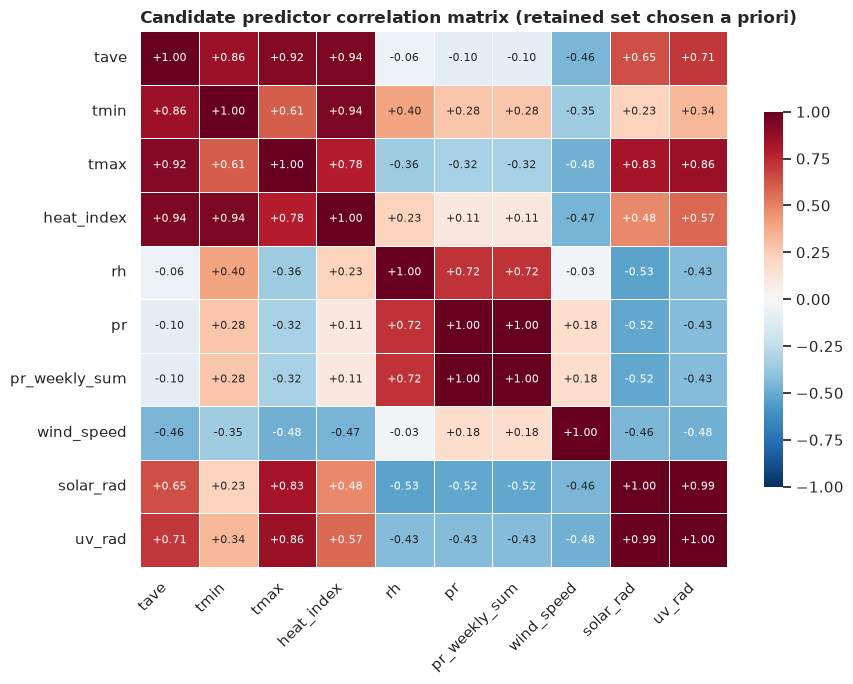

In [21]:
print("Strongly correlated candidate pairs (|r| > 0.8):")
corr = df[CANDIDATES].corr()
for i in CANDIDATES:
    for j in CANDIDATES:
        if i < j and abs(corr.loc[i,j]) > 0.8:
            print(f"  {i:14s} vs {j:14s}  r = {corr.loc[i,j]:+.2f}")

print("\nFull candidate-set VIF (shows the redundancy the block choices resolve):")
print(vif_table(df, CANDIDATES).to_string(index=False))

print(f"\nA-priori retained set: {RETAINED}")
print("Confirmatory VIF on the retained set:")
vt = vif_table(df, RETAINED); print(vt.to_string(index=False))
assert vt["VIF"].max() < VIF_THRESHOLD, "a retained predictor exceeds the VIF threshold"

plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt="+.2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.5, linecolor="white", cbar_kws={"shrink":.7}, annot_kws={"size":8})
plt.title("Candidate predictor correlation matrix (retained set chosen a priori)",
          fontsize=12, fontweight="bold", loc="left")
plt.xticks(rotation=45, ha="right"); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

##### Step 7 — Deseasonalized lag selection
Raw cross-correlation between two strongly seasonal series peaks wherever their annual cycles line
up — a calendar artifact, not a mechanistic lag. We therefore **deseasonalize both series first**
(remove annual + semi-annual harmonics and trend) and select each predictor's lag from the
residual CCF within a biologically plausible window. The raw CCF is plotted alongside only to
document the seasonal confound.

predictor      sel.lag  r_des@lag  raw peak   raw r
tave                 1      -0.07        16   +0.45
rh                   4      +0.19         4   +0.59
pr_weekly_sum        4      +0.11         4   +0.47
wind_speed           4      +0.05        14   -0.20
solar_rad            4      -0.14         1   -0.42

Selected lags (weeks): {'tave': 1, 'rh': 4, 'pr_weekly_sum': 4, 'wind_speed': 4, 'solar_rad': 4}


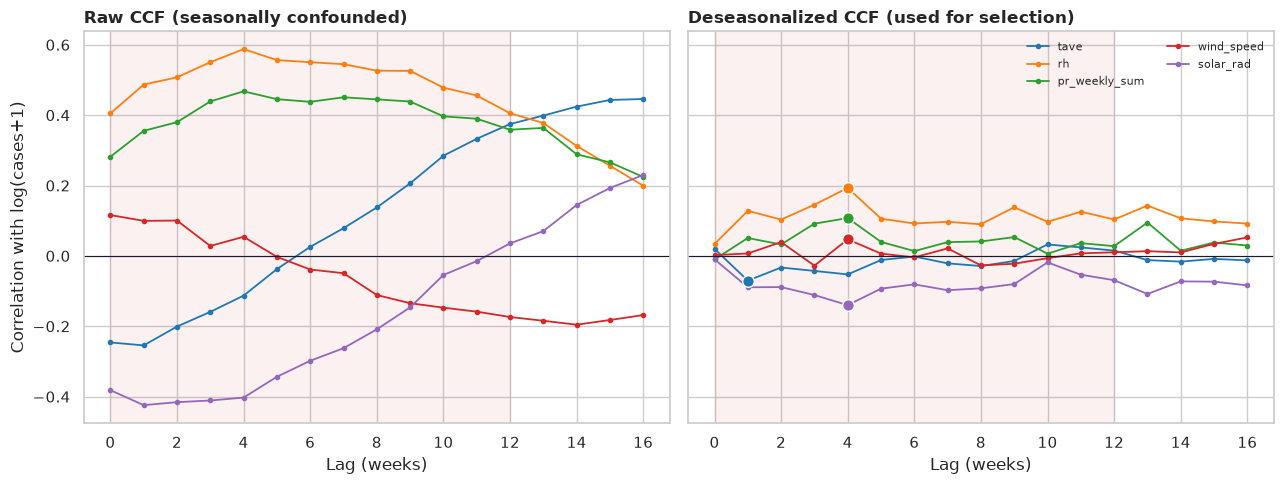

In [22]:
seas_full = seasonal_matrix(df["date"], T0)
y_anom = deseasonalize(df["log_cases"], seas_full)

lags, ccf_raw, ccf_des = {}, {}, {}
print(f"{'predictor':14s} {'sel.lag':>7s} {'r_des@lag':>10s} {'raw peak':>9s} {'raw r':>7s}")
for c in RETAINED:
    x_raw  = df[c].values.astype(float)
    x_anom = deseasonalize(x_raw, seas_full)
    rr, rd = [], []
    for L in range(0, MAXLAG+1):
        xr = pd.Series(x_raw ).shift(L); xd = pd.Series(x_anom).shift(L)
        m = xr.notna().values
        rr.append(np.corrcoef(df["log_cases"].values[m], xr.values[m])[0,1])
        rd.append(np.corrcoef(y_anom[m],               xd.values[m])[0,1])
    rr, rd = np.array(rr), np.array(rd)
    win = np.arange(PLAUSIBLE[0], PLAUSIBLE[1]+1)
    sel = int(win[np.nanargmax(np.abs(rd[win]))])
    lags[c] = sel; ccf_raw[c] = rr; ccf_des[c] = rd
    rawpeak = int(np.nanargmax(np.abs(rr)))
    print(f"{c:14s} {sel:7d} {rd[sel]:+10.2f} {rawpeak:9d} {rr[rawpeak]:+7.2f}")
print("\nSelected lags (weeks):", lags)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13,5), sharey=True)
pal = sns.color_palette("tab10", len(RETAINED))
Ls = np.arange(0, MAXLAG+1)
for c, col in zip(RETAINED, pal):
    axL.plot(Ls, ccf_raw[c], marker="o", ms=3, lw=1.3, color=col, label=c)
    axR.plot(Ls, ccf_des[c], marker="o", ms=3, lw=1.3, color=col, label=c)
    axR.scatter([lags[c]], [ccf_des[c][lags[c]]], s=70, color=col, edgecolor="white", zorder=5)
for ax, t in ((axL,"Raw CCF (seasonally confounded)"), (axR,"Deseasonalized CCF (used for selection)")):
    ax.axhline(0, color=INK, lw=.8); ax.axvspan(*PLAUSIBLE, color=ACC, alpha=0.06)
    ax.set_title(t, fontsize=12, fontweight="bold", loc="left"); ax.set_xlabel("Lag (weeks)")
axL.set_ylabel("Correlation with log(cases+1)"); axR.legend(fontsize=8, frameon=False, ncol=2)
plt.tight_layout(); plt.show()

##### Step 8 — Model specification *(III-E)*
`log(cases+1)` regressed on the retained predictors **each at its selected lag** (standardized so
coefficients are comparable), plus explicit annual + semi-annual harmonics and a linear trend to
absorb the seasonal cycle. Deseasonalizing was only for *lag selection*; the model itself keeps the
raw lagged predictors and controls season directly.

In [23]:
lagged = pd.DataFrame({c: df[c].shift(L) for c, L in lags.items()})
model_df = pd.concat([df[["date","log_cases","dengue_cases"]], lagged], axis=1).dropna().reset_index(drop=True)
print("Design rows after lagging:", len(model_df))

Z = (model_df[RETAINED] - model_df[RETAINED].mean()) / model_df[RETAINED].std()  # standardized climate
seas_m = seasonal_matrix(model_df["date"], T0)
X = np.column_stack([Z.values, seas_m])
Xc = sm.add_constant(X)
Xnames = ["const"] + RETAINED + SEAS_COLS
y = model_df["log_cases"].values
print("Terms:", Xnames)

Design rows after lagging: 776
Terms: ['const', 'tave', 'rh', 'pr_weekly_sum', 'wind_speed', 'solar_rad', 'sin1', 'cos1', 'sin2', 'cos2', 'trend']


##### Step 9 — Fit and selection
OLS estimates with 95% confidence intervals and standardized β (Table IV). An AIC comparison against an annual-only specification checks whether the semi-annual harmonic earns its place.

         term   beta  ci_low  ci_high      p
        const +1.723  +1.611   +1.834 +0.000
         tave -0.076  -0.165   +0.013 +0.094
           rh +0.237  +0.119   +0.354 +0.000
pr_weekly_sum +0.022  -0.082   +0.126 +0.677
   wind_speed +0.029  -0.037   +0.096 +0.387
    solar_rad +0.006  -0.115   +0.128 +0.916
         sin1 -0.577  -0.708   -0.447 +0.000
         cos1 -0.064  -0.219   +0.091 +0.418
         sin2 +0.186  +0.083   +0.288 +0.000
         cos2 +0.049  -0.036   +0.134 +0.259
        trend +0.004  -0.009   +0.017 +0.577

adj R^2 = 0.447   F = 63.6 (p = 1.38e-93)   AIC = 1749.3
annual+semiannual AIC = 1749.3   |   annual-only AIC = 1758.0   -> keep semiannual


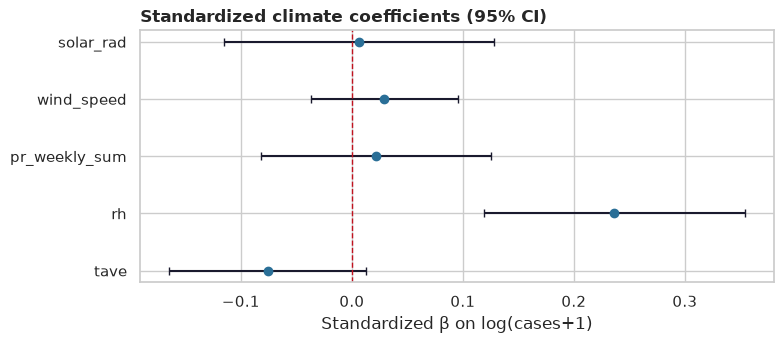

In [24]:
ols = sm.OLS(y, Xc).fit()
ci = ols.conf_int()
res = pd.DataFrame({"term":Xnames, "beta":ols.params, "ci_low":ci[:,0], "ci_high":ci[:,1], "p":ols.pvalues})
print(res.to_string(index=False, float_format=lambda v: f"{v:+.3f}"))
print(f"\nadj R^2 = {ols.rsquared_adj:.3f}   F = {ols.fvalue:.1f} (p = {ols.f_pvalue:.2e})   AIC = {ols.aic:.1f}")

# AIC check: annual-only (drop semiannual sin2, cos2)
keep = [n for n in Xnames if n not in ("sin2","cos2")]
idx  = [Xnames.index(n) for n in keep]
ols_annual = sm.OLS(y, Xc[:, idx]).fit()
print(f"annual+semiannual AIC = {ols.aic:.1f}   |   annual-only AIC = {ols_annual.aic:.1f}"
      f"   -> {'keep semiannual' if ols.aic < ols_annual.aic else 'drop semiannual'}")

clim = res[res['term'].isin(RETAINED)]
plt.figure(figsize=(8,3.6))
plt.errorbar(clim['beta'], clim['term'],
             xerr=[clim['beta']-clim['ci_low'], clim['ci_high']-clim['beta']],
             fmt='o', color=ACC2, ecolor=INK, capsize=3)
plt.axvline(0, color=ACC, ls='--', lw=1)
plt.title("Standardized climate coefficients (95% CI)", fontsize=12, fontweight="bold", loc="left")
plt.xlabel("Standardized β on log(cases+1)"); plt.tight_layout(); plt.show()

##### Step 10 — Diagnostics *(IV-D)*
Residual normality (Q–Q, Shapiro–Wilk), homoscedasticity (Breusch–Pagan), independence
(Durbin–Watson), and final VIF. If DW falls outside the ~1.5–2.5 band, the autocorrelation branch
runs: coefficients are re-reported with Newey–West (HAC) standard errors, and a lagged-case
autoregressive term is added as a secondary specification.

Durbin-Watson: 0.90   Shapiro-Wilk W=0.987 (p=3.23e-06)   Breusch-Pagan LM=26.7 (p=2.90e-03)

Final-model climate VIF:
          var      VIF
    solar_rad 2.794572
           rh 2.697975
pr_weekly_sum 2.414540
   wind_speed 1.522472
         tave 1.484970


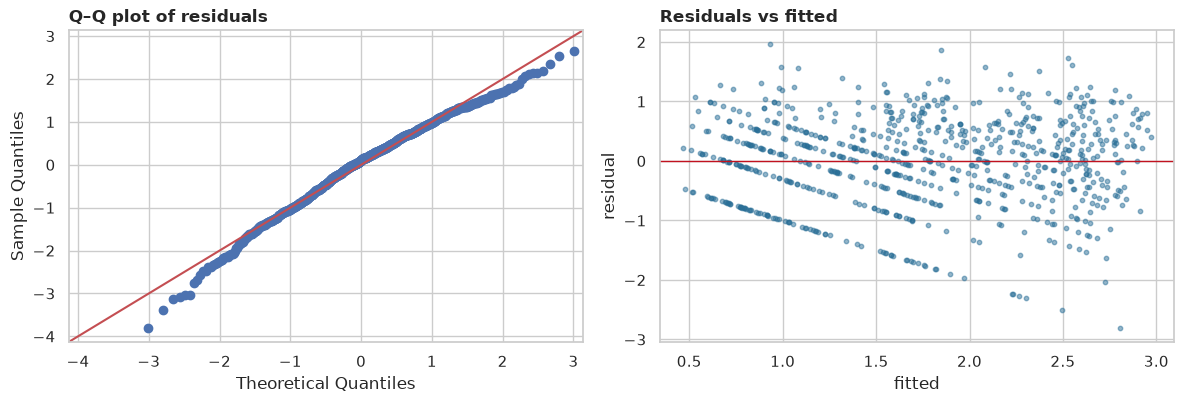


[AUTOCORRELATION FLAGGED: DW=0.90] -> Newey-West HAC SEs + AR-augmented model

HAC-corrected inference:
         term   beta  p_HAC
         tave -0.076 +0.128
           rh +0.237 +0.001
pr_weekly_sum +0.022 +0.685
   wind_speed +0.029 +0.515
    solar_rad +0.006 +0.917

AR(1)-augmented model: adj R^2=0.614  DW=2.32  AR(1) coef=+0.548 (p=7.06e-62)


In [25]:
resid = ols.resid
dw = durbin_watson(resid)
sh = stats.shapiro(resid)
bp = het_breuschpagan(resid, Xc)   # LM stat, LM p, F, F p
print(f"Durbin-Watson: {dw:.2f}   Shapiro-Wilk W={sh.statistic:.3f} (p={sh.pvalue:.2e})   "
      f"Breusch-Pagan LM={bp[0]:.1f} (p={bp[1]:.2e})")
print("\nFinal-model climate VIF:"); print(vif_table(model_df, RETAINED).to_string(index=False))

fig, (a,b) = plt.subplots(1,2, figsize=(12,4.2))
sm.qqplot(resid, line="45", fit=True, ax=a); a.set_title("Q–Q plot of residuals", fontweight="bold", loc="left")
b.scatter(ols.fittedvalues, resid, s=10, alpha=.5, color=ACC2); b.axhline(0, color=ACC, lw=1)
b.set_xlabel("fitted"); b.set_ylabel("residual"); b.set_title("Residuals vs fitted", fontweight="bold", loc="left")
plt.tight_layout(); plt.show()

if not (DW_OK[0] <= dw <= DW_OK[1]):
    print(f"\n[AUTOCORRELATION FLAGGED: DW={dw:.2f}] -> Newey-West HAC SEs + AR-augmented model")
    ols_hac = sm.OLS(y, Xc).fit(cov_type="HAC", cov_kwds={"maxlags":4})
    hac = pd.DataFrame({"term":Xnames, "beta":ols_hac.params, "p_HAC":ols_hac.pvalues})
    print("\nHAC-corrected inference:"); print(hac[hac.term.isin(RETAINED)].to_string(index=False, float_format=lambda v:f"{v:+.3f}"))

    ar_df = model_df.copy(); ar_df["ar1"] = ar_df["log_cases"].shift(1)
    ar_df = ar_df.dropna().reset_index(drop=True)
    Zar = (ar_df[RETAINED]-ar_df[RETAINED].mean())/ar_df[RETAINED].std()
    Xar = sm.add_constant(np.column_stack([Zar.values, seasonal_matrix(ar_df["date"], T0), ar_df["ar1"].values]))
    ols_ar = sm.OLS(ar_df["log_cases"].values, Xar).fit()
    print(f"\nAR(1)-augmented model: adj R^2={ols_ar.rsquared_adj:.3f}  DW={durbin_watson(ols_ar.resid):.2f}  "
          f"AR(1) coef={ols_ar.params[-1]:+.3f} (p={ols_ar.pvalues[-1]:.2e})")
else:
    print("\nNo autocorrelation flagged; primary OLS retained without an AR term.")

##### Step 11 — Rolling-origin validation
Expanding-window cross-validation across the whole series (5-year initial train, 26-week test
blocks), refitting per fold with scaling fit on the training data only. A fixed 2020–2022 hold-out
is avoided because the 2019 record epidemic and the 2020–2021 COVID disruption make that window
non-representative.

folds=20   log-scale: RMSE=0.867 MAE=0.673 R^2=0.226   count-scale: RMSE=8.2 MAE=5.8


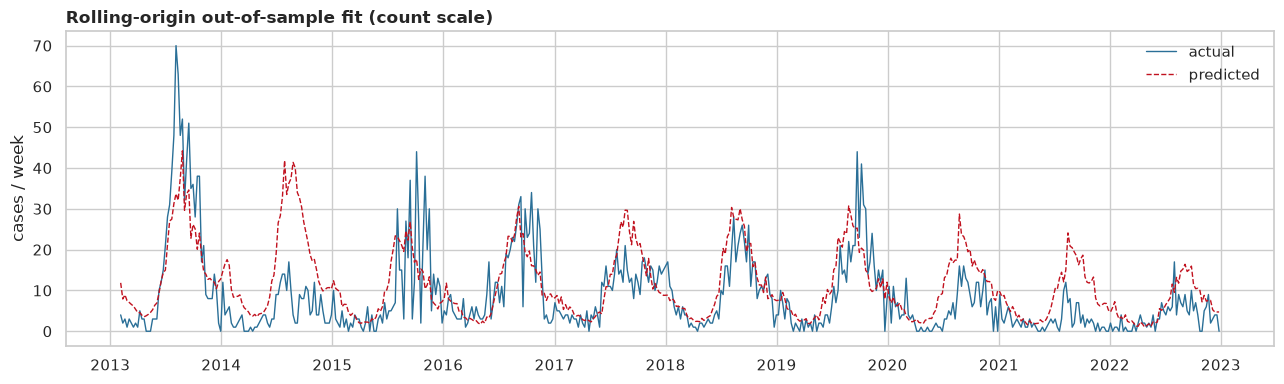

In [26]:
rows = []
start = CV_INIT
while start + 1 < len(model_df):
    tr = slice(0, start); te = slice(start, min(start+CV_HORIZON, len(model_df)))
    mu, sd = model_df[RETAINED].iloc[tr].mean(), model_df[RETAINED].iloc[tr].std()
    Ztr = (model_df[RETAINED].iloc[tr]-mu)/sd; Zte = (model_df[RETAINED].iloc[te]-mu)/sd
    Xtr = sm.add_constant(np.column_stack([Ztr.values, seasonal_matrix(model_df["date"].iloc[tr], T0)]), has_constant="add")
    Xte = sm.add_constant(np.column_stack([Zte.values, seasonal_matrix(model_df["date"].iloc[te], T0)]), has_constant="add")
    fit = sm.OLS(model_df["log_cases"].values[tr], Xtr).fit()
    rows.append((model_df["log_cases"].values[te], (Xte @ fit.params)))
    start += CV_HORIZON

yt = np.concatenate([r[0] for r in rows]); yp = np.concatenate([r[1] for r in rows])
rmse = np.sqrt(np.mean((yt-yp)**2)); mae = np.mean(np.abs(yt-yp))
r2 = 1 - ((yt-yp)**2).sum()/((yt-yt.mean())**2).sum()
ct, cp = np.expm1(yt), np.expm1(yp)
print(f"folds={len(rows)}   log-scale: RMSE={rmse:.3f} MAE={mae:.3f} R^2={r2:.3f}   "
      f"count-scale: RMSE={np.sqrt(np.mean((ct-cp)**2)):.1f} MAE={np.mean(np.abs(ct-cp)):.1f}")

oos_dates = model_df["date"].iloc[CV_INIT:CV_INIT+len(yt)]
plt.figure(figsize=(13,4))
plt.plot(oos_dates, np.expm1(yt), color=ACC2, lw=1, label="actual")
plt.plot(oos_dates, np.expm1(yp), color=ACC, lw=1, ls="--", label="predicted")
plt.title("Rolling-origin out-of-sample fit (count scale)", fontsize=12, fontweight="bold", loc="left")
plt.ylabel("cases / week"); plt.legend(frameon=False); plt.tight_layout(); plt.show()

##### Step 12 — Negative Binomial robustness *(IV-F)*
The counts are overdispersed, so OLS-on-log is refit as a Negative Binomial GLM on the raw counts
(same lagged predictors, harmonics, and trend). The check is whether coefficient **signs and
significance** agree with the OLS baseline — if so, the interpretable linear model is defensible.

In [27]:
from statsmodels.discrete.discrete_model import NegativeBinomial
yc = model_df["dengue_cases"].values.astype(float)
try:
    nb = NegativeBinomial(yc, Xc).fit(disp=0, maxiter=200)
    nb_params, nb_p, label = nb.params[:len(Xnames)], nb.pvalues[:len(Xnames)], "Negative Binomial"
except Exception as e:
    print("NB did not converge, falling back to Poisson GLM:", e)
    po = sm.GLM(yc, Xc, family=sm.families.Poisson()).fit()
    nb_params, nb_p, label = po.params, po.pvalues, "Poisson (fallback)"

cmp = pd.DataFrame({
    "term": Xnames,
    "OLS_beta": ols.params, "OLS_p": ols.pvalues,
    f"{label}_coef": nb_params, f"{label}_p": nb_p,
}).query("term in @RETAINED")
cmp["sign_agrees"] = np.sign(cmp["OLS_beta"]) == np.sign(cmp[f"{label}_coef"])
print(cmp.to_string(index=False, float_format=lambda v: f"{v:+.3f}"))

         term  OLS_beta  OLS_p  Negative Binomial_coef  Negative Binomial_p  sign_agrees
         tave    -0.076 +0.094                  -0.085               +0.106         True
           rh    +0.237 +0.000                  +0.260               +0.000         True
pr_weekly_sum    +0.022 +0.677                  -0.010               +0.852        False
   wind_speed    +0.029 +0.387                  +0.036               +0.315         True
    solar_rad    +0.006 +0.916                  -0.026               +0.707        False


##### Step 13 — Interpretation and reporting
A tidy summary — each predictor's selected lag, standardized OLS effect with CI and p, and NB sign agreement — plus a one-line readout of the dominant association to seed the Discussion.

In [28]:
summary = (res[res.term.isin(RETAINED)]
           .assign(lag=[lags[t] for t in res[res.term.isin(RETAINED)].term])
           .merge(cmp[["term","sign_agrees"]], on="term")
           [["term","lag","beta","ci_low","ci_high","p","sign_agrees"]]
           .rename(columns={"term":"predictor","beta":"std_beta"}))
print(summary.to_string(index=False, float_format=lambda v: f"{v:+.3f}"))

sig = summary[summary.p < 0.05].reindex(summary[summary.p < 0.05].std_beta.abs().sort_values(ascending=False).index)
if len(sig):
    top = sig.iloc[0]
    direction = "higher" if top.std_beta > 0 else "lower"
    print(f"\nDominant association: {top.predictor} at a {int(top.lag)}-week lag "
          f"(standardized β = {top.std_beta:+.2f}, p = {top.p:.1e}) — {direction} values precede higher weekly cases.")
else:
    print("\nNo climate predictor reached p < 0.05 at its selected lag.")

    predictor  lag  std_beta  ci_low  ci_high      p  sign_agrees
         tave    1    -0.076  -0.165   +0.013 +0.094         True
           rh    4    +0.237  +0.119   +0.354 +0.000         True
pr_weekly_sum    4    +0.022  -0.082   +0.126 +0.677        False
   wind_speed    4    +0.029  -0.037   +0.096 +0.387         True
    solar_rad    4    +0.006  -0.115   +0.128 +0.916        False

Dominant association: rh at a 4-week lag (standardized β = +0.24, p = 8.9e-05) — higher values precede higher weekly cases.


---
###### Notes and limitations
- **Association, not causation** — an ecological, single-site design; coefficients describe direction and magnitude only.
- **OLS on log-counts** is the interpretable baseline; Step 12's NB refit is the robustness anchor. Report both.
- **Residual autocorrelation** is expected in weekly series; the Step 10 branch reports HAC SEs and an AR-augmented spec when DW flags it.
- **Validation** uses rolling origins by design; do not quote a single 2020–2022 hold-out without the COVID/epidemic caveat.
- **Sensitivity refit:** set `RETAINED = ["tmin","rh","pr_weekly_sum","wind_speed","solar_rad"]` and re-run to confirm conclusions hold when `tmin` replaces `tave`.